BANK CUSTOMER CHURN ANN PROJECT
------
CLASSIFICATION PROBLEM(catergorical)

--The objective of this project is to develop an Artificial Neural Network (ANN) model that can predict whether a customer will churn or continue with the bank based on factors such as credit score, age, balance, tenure, number of products, and estimated salary.

In [1]:
import sys
print(sys.version)

3.12.7 | packaged by Anaconda, Inc. | (main, Oct  4 2024, 13:17:27) [MSC v.1929 64 bit (AMD64)]


In [2]:
!pip install --upgrade pip
!pip install tensorflow

  Using cached pip-26.1.2-py3-none-any.whl.metadata (4.6 kB)
Using cached pip-26.1.2-py3-none-any.whl (1.8 MB)


ERROR: To modify pip, please run the following command:
C:\Users\Dell\anaconda3\python.exe -m pip install --upgrade pip


In [3]:
#importing basic libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import kagglehub 
import os

In [4]:
#get the dataset
df = pd.read_csv("Bank Customer Churn Prediction.csv")
df.head()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [5]:
df.tail()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
9995,15606229,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,15569892,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,15584532,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,15682355,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1
9999,15628319,792,France,Female,28,4,130142.79,1,1,0,38190.78,0


In [6]:
#(rows,columns)
df.shape

(10000, 12)

In [7]:
df.columns

Index(['customer_id', 'credit_score', 'country', 'gender', 'age', 'tenure',
       'balance', 'products_number', 'credit_card', 'active_member',
       'estimated_salary', 'churn'],
      dtype='object')

In [8]:
#Stastical summary of numerical columns
df.describe()

,customer_id,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
count,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [9]:
#null values and dtypes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       10000 non-null  int64  
 1   credit_score      10000 non-null  int64  
 2   country           10000 non-null  object 
 3   gender            10000 non-null  object 
 4   age               10000 non-null  int64  
 5   tenure            10000 non-null  int64  
 6   balance           10000 non-null  float64
 7   products_number   10000 non-null  int64  
 8   credit_card       10000 non-null  int64  
 9   active_member     10000 non-null  int64  
 10  estimated_salary  10000 non-null  float64
 11  churn             10000 non-null  int64  
dtypes: float64(2), int64(8), object(2)
memory usage: 937.6+ KB


Feature Engineering.

In [10]:
#Divide dataset in dependent features and independent features
a = df.iloc[: ,1:11]
a.head()

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary
0,619,France,Female,42,2,0.00,1,1,1,101348.88
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58
2,502,France,Female,42,8,159660.80,3,1,0,113931.57
3,699,France,Female,39,1,0.00,2,0,0,93826.63
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10


In [11]:
a.shape

(10000, 10)

In [12]:
b = df.iloc[: ,-1:] 
b.head()

,churn
0,1
1,0
2,1
3,0
4,0


In [13]:
b.shape

(10000, 1)

In [14]:
a.columns

Index(['credit_score', 'country', 'gender', 'age', 'tenure', 'balance',
       'products_number', 'credit_card', 'active_member', 'estimated_salary'],
      dtype='object')

In [15]:
#converting categorical data into binary data
#handling the categorical features
Gender=pd.get_dummies(a['gender'],dtype=int)

In [16]:
Country = pd.get_dummies(a['country'],dtype = int)
Country.head()

,France,Germany,Spain
0,1,0,0
1,0,0,1
2,1,0,0
3,1,0,0
4,0,0,1


In [17]:
#dropping old columns and adding new one.
a = a.drop(['gender','country'],axis=1)

In [18]:
a.head()

,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary
0,619,42,2,0.00,1,1,1,101348.88
1,608,41,1,83807.86,1,0,1,112542.58
2,502,42,8,159660.80,3,1,0,113931.57
3,699,39,1,0.00,2,0,0,93826.63
4,850,43,2,125510.82,1,1,1,79084.10


In [19]:
a = pd.concat([a,Country,Gender], axis = 1)

In [20]:
a.head()

,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,France,Germany,Spain,Female,Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,1,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,1,0
3,699,39,1,0.00,2,0,0,93826.63,1,0,0,1,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,1,0


In [21]:
a.shape

(10000, 13)

In [22]:
a.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   credit_score      10000 non-null  int64  
 1   age               10000 non-null  int64  
 2   tenure            10000 non-null  int64  
 3   balance           10000 non-null  float64
 4   products_number   10000 non-null  int64  
 5   credit_card       10000 non-null  int64  
 6   active_member     10000 non-null  int64  
 7   estimated_salary  10000 non-null  float64
 8   France            10000 non-null  int32  
 9   Germany           10000 non-null  int32  
 10  Spain             10000 non-null  int32  
 11  Female            10000 non-null  int32  
 12  Male              10000 non-null  int32  
dtypes: float64(2), int32(5), int64(6)
memory usage: 820.4 KB


In [23]:
#splitting dataset into training and test dataset.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [24]:
x_train,x_test,y_train,y_test = train_test_split(a,b, test_size = 0.2, random_state = 0)

In [25]:
sc = StandardScaler()

In [26]:
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

In [27]:
x_train

array([[ 0.16958176, -0.46460796,  0.00666099, ...,  1.74309049,
         1.09168714, -1.09168714],
       [-2.30455945,  0.30102557, -1.37744033, ..., -0.57369368,
        -0.91601335,  0.91601335],
       [-1.19119591, -0.94312892, -1.031415  , ..., -0.57369368,
         1.09168714, -1.09168714],
       ...,
       [ 0.9015152 , -0.36890377,  0.00666099, ..., -0.57369368,
        -0.91601335,  0.91601335],
       [-0.62420521, -0.08179119,  1.39076231, ...,  1.74309049,
         1.09168714, -1.09168714],
       [-0.28401079,  0.87525072, -1.37744033, ..., -0.57369368,
         1.09168714, -1.09168714]])

In [28]:
x_test

array([[-0.55204276, -0.36890377,  1.04473698, ..., -0.57369368,
         1.09168714, -1.09168714],
       [-1.31490297,  0.10961719, -1.031415  , ..., -0.57369368,
         1.09168714, -1.09168714],
       [ 0.57162971,  0.30102557,  1.04473698, ...,  1.74309049,
         1.09168714, -1.09168714],
       ...,
       [-0.74791227, -0.27319958, -1.37744033, ...,  1.74309049,
        -0.91601335,  0.91601335],
       [-0.00566991, -0.46460796, -0.33936434, ..., -0.57369368,
        -0.91601335,  0.91601335],
       [-0.79945688, -0.84742473,  1.04473698, ..., -0.57369368,
        -0.91601335,  0.91601335]])

In [29]:
x_train.shape

(8000, 13)

In [30]:
#Creating ANN
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LeakyReLU,PReLU,ELU,ReLU
from tensorflow.keras.layers import Dropout 

In [31]:
classifier=Sequential()

In [32]:
#adding the input layer
classifier.add(Dense(units=12 ,kernel_initializer="he_uniform", activation="relu" ,input_dim = 13))

c:\Users\Dell\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [33]:
#Adding hidden layers
classifier.add(Dense(units = 9 , activation ="relu")) #1st
classifier.add(Dropout(0.3))
classifier.add(Dense(units = 7 , activation ="relu")) #2nd
classifier.add(Dropout(0.4))
classifier.add(Dense(units = 6 , activation="relu")) #3rd
classifier.add(Dropout(0.2))

In [34]:
#Adding output layer
classifier.add(Dense(units = 1 , activation ="sigmoid"))

In [35]:
classifier.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12)             │           168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │           117 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 9)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │            70 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │             7 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 410 (1.60 KB)

 Trainable params: 410 (1.60 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
classifier.compile(optimizer='Adam', loss='binary_crossentropy', metrics=['accuracy'])

In [37]:
#Early stopping
import tensorflow as tf
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    min_delta=0.001,
    patience= 20,
    verbose = 1 ,
    mode = "auto",
    baseline = None,
    restore_best_weights= False ,
)

In [38]:
# import tensorflow as tf
# print(tf.__version__)

In [39]:
model =classifier.fit(x_train,y_train,validation_split=0.33 , batch_size= 10, epochs = 60  , callbacks = early_stopping)

Epoch 1/60
536/536 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.7733 - loss: 0.5664 - val_accuracy: 0.7955 - val_loss: 0.4907
Epoch 2/60
536/536 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7953 - loss: 0.5048 - val_accuracy: 0.7955 - val_loss: 0.4758
Epoch 3/60
536/536 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7960 - loss: 0.4904 - val_accuracy: 0.7955 - val_loss: 0.4666
Epoch 4/60
536/536 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7960 - loss: 0.4803 - val_accuracy: 0.7955 - val_loss: 0.4576
Epoch 5/60
536/536 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7962 - loss: 0.4748 - val_accuracy: 0.7955 - val_loss: 0.4552
Epoch 6/60
536/536 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7962 - loss: 0.4673 - val_accuracy: 0.7955 - val_loss: 0.4493
Epoch 7/60
536/536 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7962 - loss: 0.4552 - val_accuracy: 0.7955 - val_loss: 0.4416
Epoch 8/60
536/536 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7962 - loss: 0.4522 - val_accuracy: 0

In [40]:
model.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

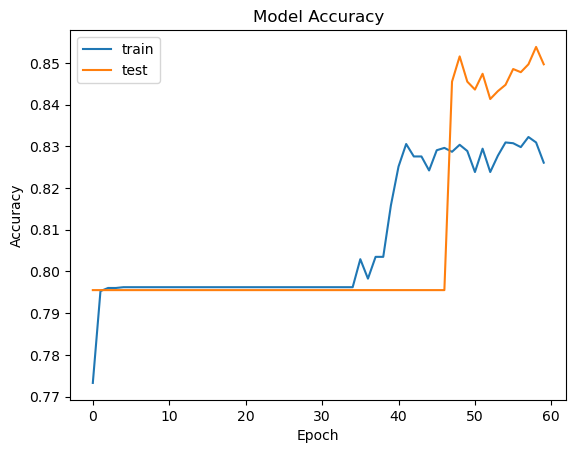

In [41]:
#Summarize history for accuracy
plt.plot(model.history['accuracy'])
plt.plot(model.history['val_accuracy'])
plt.title("Model Accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Epoch")
plt.legend(['train','test'],loc = 'upper left')
plt.show()

In [42]:
#Predict the model
y_pred = classifier.predict(x_test)
y_pred = (y_pred > 0.5)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [43]:
from sklearn.metrics import confusion_matrix
mt = confusion_matrix(y_test,y_pred)

In [44]:
mt

array([[1486,  109],
       [ 179,  226]], dtype=int64)

In [45]:
classifier.get_weights()

[array([[ 0.37993878, -0.5919176 ,  0.37908208, -0.01084391,  0.02188998,
         -0.1439775 , -0.21119738, -0.1303059 , -0.10486719, -0.11138213,
          0.2816415 , -0.21139874],
        [-0.80497736,  0.00302933,  0.06711632,  1.1512451 ,  0.26761416,
          0.04238781,  0.19998227,  0.15899052,  0.8706837 ,  0.09904989,
          0.34287295, -0.4747552 ],
        [-0.2082865 , -0.18500154,  0.24909453,  0.03031461,  0.3624783 ,
         -0.34825432, -0.00921912, -0.17192753,  0.01000551,  0.04804435,
          0.05098492, -0.05209028],
        [-0.5363745 ,  0.01259108,  0.05712168,  0.23186456, -0.34978414,
          0.22888206, -1.0091537 ,  0.24005845, -0.23214898,  0.19273971,
          0.31514153,  0.03146464],
        [ 0.16968668,  0.3069984 ,  0.09075245, -0.70135385, -0.10389771,
         -0.20629804, -1.4930763 ,  1.5124415 ,  0.8234444 ,  0.26015225,
         -0.47841486,  0.13815029],
        [ 0.11316578, -0.08487023,  0.11448169, -0.19274288, -0.24752331,
      

In [46]:
from sklearn.metrics import accuracy_score
s = accuracy_score(y_test,y_pred)
acc = (f"The Accuracy Score is : {s} . ")
print(acc)

The Accuracy Score is : 0.856 . 
